# Exercise 2: Convolutional Neural Network (CNN) Classifier

**Module:** PUSL3123 AI and Machine Learning | **Dataset:** CIFAR-10  
**Aim:** Implement a CNN with three trainable layers, train it under the same settings as the MLP and compare the two.

**Requirements:** Python 3.9+, `torch`, `torchvision`, `numpy`, `pandas`, `matplotlib`, `jupyter`  
(`pip install torch torchvision numpy pandas matplotlib jupyter`)

**How to reproduce:** run all cells from top to bottom (Kernel > Restart & Run All). CIFAR-10 downloads automatically to `./data`. A fixed seed (42), an 80:20 train/validation split of the official training set, and identical settings (batch size 128, 10 epochs, Adam, lr 1e-3) are used throughout. The official test set is never used for training, tuning or model selection.

In [1]:
# CNN classifier and comparison with the MLP 

import random, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms
from IPython.display import display


SEED = 42
BATCH_SIZE = 128
EPOCHS = 10
LEARNING_RATE = 1e-3
NUM_WORKERS = 0
DATA_DIR = "./data"
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed()

# Data preparation
mean = (0.4914, 0.4822, 0.4465)
std = (0.2470, 0.2435, 0.2616)
transform = transforms.Compose([transforms.ToTensor(), transforms.Normalize(mean, std)])

full_train = datasets.CIFAR10(DATA_DIR, train=True, download=True, transform=transform)
test_set = datasets.CIFAR10(DATA_DIR, train=False, download=True, transform=transform)

train_size = int(0.8 * len(full_train))
val_size = len(full_train) - train_size
train_set, val_set = random_split(full_train, [train_size, val_size],
                                  generator=torch.Generator().manual_seed(SEED))

train_loader = DataLoader(train_set, BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS)
val_loader = DataLoader(val_set, BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)
test_loader = DataLoader(test_set, BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)
print(f"Device: {DEVICE} | Train: {len(train_set)} | Val: {len(val_set)} | Test: {len(test_set)}")

Device: cpu | Train: 40000 | Val: 10000 | Test: 10000


In [2]:
# Models
class MLPClassifier(nn.Module):
    """Three trainable layers: Linear -> Linear -> Linear."""
    def __init__(self):
        super().__init__()
        self.network = nn.Sequential(
            nn.Flatten(),
            nn.Linear(3 * 32 * 32, 512), nn.ReLU(),
            nn.Linear(512, 256), nn.ReLU(),
            nn.Linear(256, 10),
        )
    def forward(self, x):
        return self.network(x)

class CNNClassifier(nn.Module):
    """Three trainable layers: Conv2d -> Conv2d -> Linear (pooling/ReLU have no weights)."""
    def __init__(self, dropout=0.0):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),   # 32x32 -> 16x16
            nn.Conv2d(32, 64, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),  # 16x16 -> 8x8
        )
        self.classifier = nn.Sequential(
            nn.Flatten(), nn.Dropout(dropout), nn.Linear(64 * 8 * 8, 10)
        )
    def forward(self, x):
        return self.classifier(self.features(x))

In [3]:
# ==== Helpers ====
def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

def run_epoch(model, loader, criterion, optimizer=None):
    training = optimizer is not None
    model.train() if training else model.eval()
    total_loss, correct, total = 0.0, 0, 0
    with torch.set_grad_enabled(training):
        for images, labels in loader:
            images, labels = images.to(DEVICE), labels.to(DEVICE)
            if training:
                optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            if training:
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * labels.size(0)
            correct += (outputs.argmax(1) == labels).sum().item()
            total += labels.size(0)
    return total_loss / total, correct / total

def train_model(model, train_dl, val_dl, epochs=EPOCHS, lr=LEARNING_RATE):
    model = model.to(DEVICE)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)
    hist = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    for epoch in range(epochs):
        start = time.time()
        tl, ta = run_epoch(model, train_dl, criterion, optimizer)
        vl, va = run_epoch(model, val_dl, criterion)
        for k, v in zip(hist, (tl, vl, ta, va)):
            hist[k].append(v)
        print(f"Epoch {epoch+1:02d}/{epochs} | train loss {tl:.4f} acc {ta:.4f} | "
              f"val loss {vl:.4f} acc {va:.4f} | {time.time()-start:.1f}s")
    return model, hist

def evaluate_model(model, loader, label):
    loss, acc = run_epoch(model, loader, nn.CrossEntropyLoss())
    print(f"{label}: loss={loss:.4f}, accuracy={acc*100:.2f}%")
    return loss, acc

def plot_history(hist, title):
    ep = range(1, len(hist["train_loss"]) + 1)
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].plot(ep, hist["train_loss"], "o-", label="Training")
    ax[0].plot(ep, hist["val_loss"], "o-", label="Validation")
    ax[0].set(title="Loss", xlabel="Epoch", ylabel="Cross-entropy loss"); ax[0].legend(); ax[0].grid(alpha=.3)
    ax[1].plot(ep, hist["train_acc"], "o-", label="Training")
    ax[1].plot(ep, hist["val_acc"], "o-", label="Validation")
    ax[1].set(title="Accuracy", xlabel="Epoch", ylabel="Accuracy"); ax[1].legend(); ax[1].grid(alpha=.3)
    fig.suptitle(title); plt.tight_layout(); plt.show()

MLP trainable parameters: 1,707,274
CNN trainable parameters: 60,362

--- Training MLP ---
Epoch 01/10 | train loss 1.6665 acc 0.4084 | val loss 1.5308 acc 0.4635 | 12.9s
Epoch 02/10 | train loss 1.4578 acc 0.4865 | val loss 1.4551 acc 0.4917 | 12.7s
Epoch 03/10 | train loss 1.3459 acc 0.5246 | val loss 1.4084 acc 0.5053 | 20.2s
Epoch 04/10 | train loss 1.2502 acc 0.5571 | val loss 1.4373 acc 0.5090 | 16.5s
Epoch 05/10 | train loss 1.1726 acc 0.5876 | val loss 1.4011 acc 0.5153 | 16.3s
Epoch 06/10 | train loss 1.0898 acc 0.6156 | val loss 1.4162 acc 0.5283 | 13.0s
Epoch 07/10 | train loss 1.0146 acc 0.6403 | val loss 1.4910 acc 0.5081 | 13.3s
Epoch 08/10 | train loss 0.9418 acc 0.6673 | val loss 1.4973 acc 0.5182 | 13.5s
Epoch 09/10 | train loss 0.8612 acc 0.6946 | val loss 1.5029 acc 0.5271 | 20.5s
Epoch 10/10 | train loss 0.7982 acc 0.7151 | val loss 1.5851 acc 0.5212 | 20.5s

--- Training CNN ---
Epoch 01/10 | train loss 1.4182 acc 0.4971 | val loss 1.1635 acc 0.5907 | 33.1s
Epoch 0

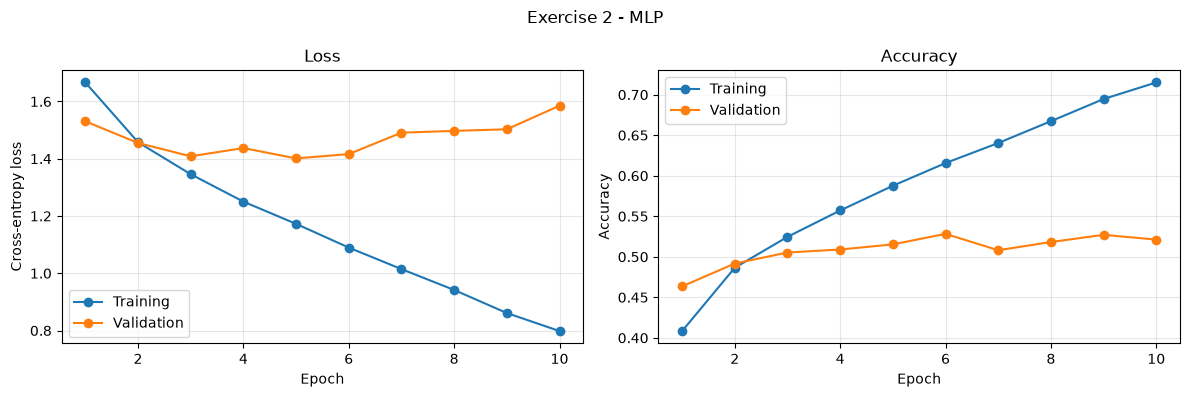

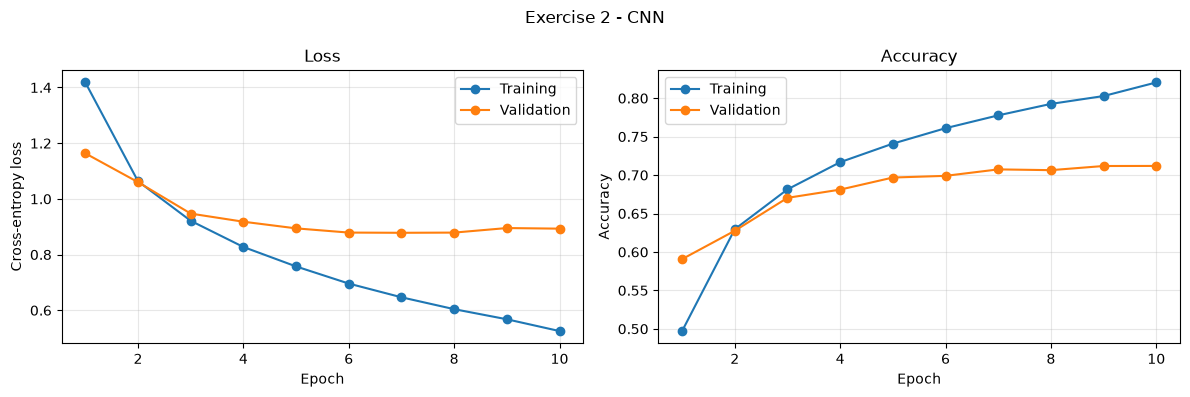

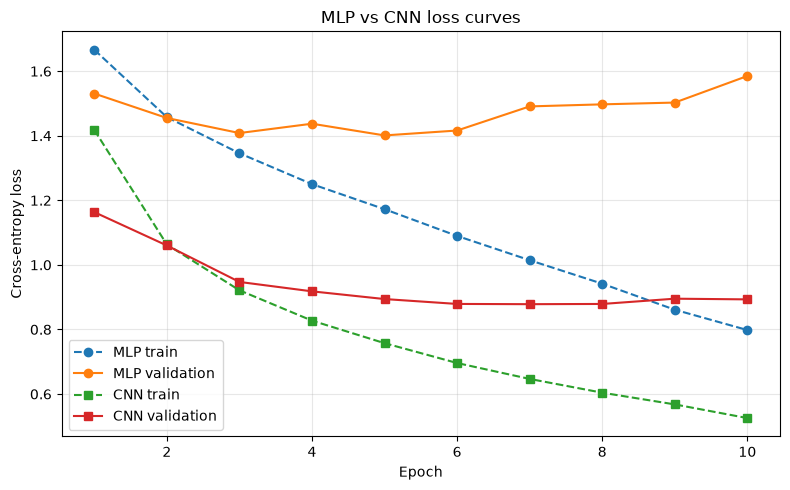

In [4]:
# ==== Train MLP and CNN with identical settings (reseeded before each) ====
set_seed(); mlp_model = MLPClassifier()
set_seed(); cnn_model = CNNClassifier()
print("MLP trainable parameters:", f"{count_parameters(mlp_model):,}")
print("CNN trainable parameters:", f"{count_parameters(cnn_model):,}")

print("\n--- Training MLP ---")
mlp_model, mlp_history = train_model(mlp_model, train_loader, val_loader)
print("\n--- Training CNN ---")
cnn_model, cnn_history = train_model(cnn_model, train_loader, val_loader)

plot_history(mlp_history, "Exercise 2 - MLP")
plot_history(cnn_history, "Exercise 2 - CNN")

# Overlay of validation/training loss for direct comparison
ep = range(1, EPOCHS + 1)
plt.figure(figsize=(8, 5))
plt.plot(ep, mlp_history["train_loss"], "o--", label="MLP train")
plt.plot(ep, mlp_history["val_loss"], "o-", label="MLP validation")
plt.plot(ep, cnn_history["train_loss"], "s--", label="CNN train")
plt.plot(ep, cnn_history["val_loss"], "s-", label="CNN validation")
plt.xlabel("Epoch"); plt.ylabel("Cross-entropy loss"); plt.title("MLP vs CNN loss curves")
plt.legend(); plt.grid(alpha=.3); plt.tight_layout(); plt.show()

MLP training: loss=0.6889, accuracy=75.72%
MLP validation: loss=1.5851, accuracy=52.12%
MLP official test: loss=1.6095, accuracy=51.35%
CNN training: loss=0.4557, accuracy=84.73%
CNN validation: loss=0.8932, accuracy=71.19%
CNN official test: loss=0.8939, accuracy=71.06%


,Model,Parameters,Train loss,Val loss,Test loss,Train acc,Val acc,Test acc
0,MLP,1707274,0.6889,1.5851,1.6095,0.7572,0.5212,0.5135
1,CNN,60362,0.4557,0.8932,0.8939,0.8474,0.7119,0.7106


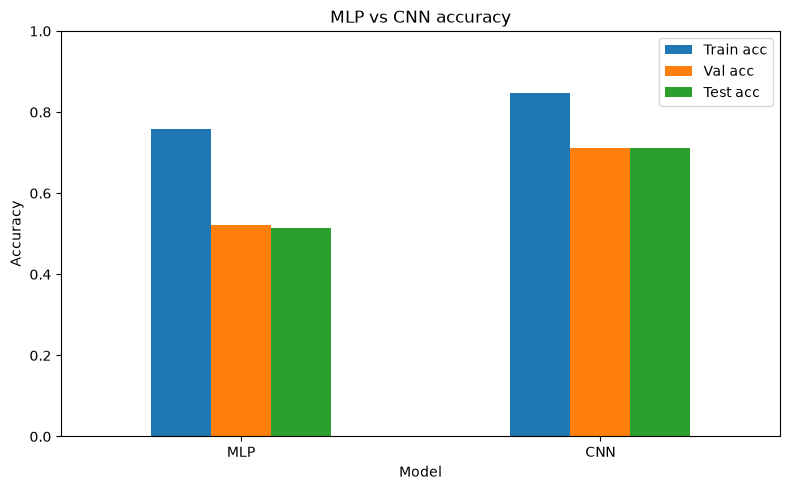

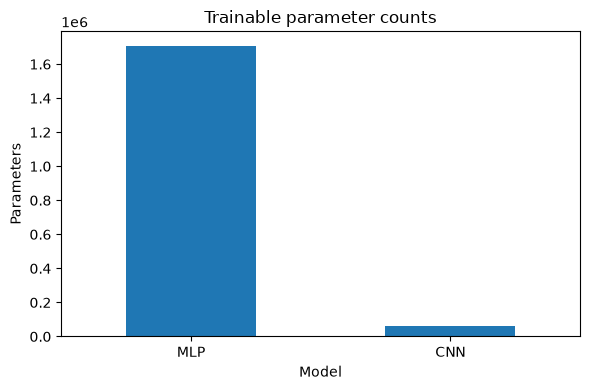

In [5]:
# Final evaluation and comparison (test set used once, after training)
rows = []
for name, model in [("MLP", mlp_model), ("CNN", cnn_model)]:
    tr_l, tr_a = evaluate_model(model, train_loader, f"{name} training")
    va_l, va_a = evaluate_model(model, val_loader, f"{name} validation")
    te_l, te_a = evaluate_model(model, test_loader, f"{name} official test")
    rows.append({"Model": name, "Parameters": count_parameters(model),
                 "Train loss": tr_l, "Val loss": va_l, "Test loss": te_l,
                 "Train acc": tr_a, "Val acc": va_a, "Test acc": te_a})
comparison = pd.DataFrame(rows)
display(comparison.round(4))

comparison.set_index("Model")[["Train acc", "Val acc", "Test acc"]].plot(
    kind="bar", ylim=(0, 1), figsize=(8, 5), title="MLP vs CNN accuracy")
plt.ylabel("Accuracy"); plt.xticks(rotation=0); plt.tight_layout(); plt.show()

comparison.set_index("Model")["Parameters"].plot(
    kind="bar", figsize=(6, 4), title="Trainable parameter counts")
plt.ylabel("Parameters"); plt.xticks(rotation=0); plt.tight_layout(); plt.show()

torch.save(cnn_model.state_dict(), "exercise2_cnn_cifar10.pth")